# 02 · Quatro perguntas sobre a dublagem brasileira

Base: `data/processed/elenco_limpo.csv`, a mesma da exploração ([01](01_exploracao.ipynb)): 420 mil papéis, 13,7 mil obras, 6,8 mil dubladores, a partir da [Dublapédia](https://dublagem.fandom.com) (CC BY-SA 3.0). O gênero dos dubladores vem da ficha e, na falta dela, do primeiro nome no Censo 2010 ([Brasil.io](https://brasil.io/dataset/genero-nomes/), CC BY-SA 4.0).

A lógica está em `scripts/questions.py`; o notebook só chama as funções, mostra agregados e desenha. Os quatro gráficos principais também são salvos em `reports/figs/`.

1. **Concentração**: quantos dubladores fazem a maior parte dos papéis?
2. **Mapa da escalação**: quem trabalha com quem, e isso separa Rio e São Paulo?
3. **Fidelidade de voz**: um ator original costuma manter o mesmo dublador?
4. **Gênero**: quanto da dublagem é feita por mulheres, e onde o gênero da voz muda?

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "scripts"))

import matplotlib.pyplot as plt
from IPython.display import Markdown, display

import explore as ex
import questions as q

ex.style()
rows = q.load()
FIGS = Path.cwd().parent / "reports" / "figs"
FIGS.mkdir(parents=True, exist_ok=True)
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]  # ordem fixa

def tabela(linhas, colunas, fmt=None):
    fmt = fmt or {}
    out = ["| " + " | ".join(colunas) + " |", "|" + "|".join("---" if i == 0 else "---:" for i in range(len(colunas))) + "|"]
    for l in linhas:
        out.append("| " + " | ".join(fmt.get(c, str)(l[c]) if isinstance(l, dict) else fmt.get(c, str)(v)
                                      for c, v in (zip(colunas, l) if not isinstance(l, dict) else ((c, None) for c in colunas))) + " |")
    display(Markdown("\n".join(out)))

p1 = lambda v: f"{v:.1f}%".replace(".", ",")
mil = lambda v: f"{v:,}".replace(",", ".")

## 1. Concentração: quem faz os papéis

Cada papel é uma linha (personagem × versão × obra) com dublador conhecido. A curva de Lorenz ordena os dubladores do menos ao mais ativo e mostra que fração dos papéis eles acumulam; quanto mais longe da diagonal, mais concentrado. O Gini resume isso entre 0 (todos fazem o mesmo número de papéis) e 1 (um só faz tudo).

In [2]:
conc = q.concentracao(rows)
tabela(conc, ["recorte", "dubladores", "papéis", "gini", "top 1%", "top 10%", "top 50"],
       {"dubladores": mil, "papéis": mil, "gini": lambda v: f"{v:.2f}".replace(".", ","), "top 1%": p1, "top 10%": p1, "top 50": p1})

| recorte | dubladores | papéis | gini | top 1% | top 10% | top 50 |
|---|---:|---:|---:|---:|---:|---:|
| todos | 6.774 | 372.283 | 0,88 | 23,6% | 84,3% | 19,1% |
| 1980s | 1.096 | 24.561 | 0,73 | 8,7% | 54,6% | 31,7% |
| 1990s | 1.732 | 47.400 | 0,79 | 13,0% | 66,0% | 29,4% |
| 2000s | 2.266 | 74.021 | 0,82 | 14,2% | 71,8% | 26,7% |
| 2010s | 3.686 | 103.776 | 0,81 | 16,2% | 71,3% | 20,6% |
| 2020s | 3.387 | 95.481 | 0,78 | 12,4% | 64,9% | 17,6% |
| live-action | 4.088 | 202.179 | 0,84 | 17,4% | 74,2% | 20,6% |
| animação | 3.362 | 76.288 | 0,80 | 17,3% | 70,3% | 23,0% |
| anime | 2.855 | 57.703 | 0,74 | 12,5% | 58,3% | 19,9% |
| game | 1.237 | 10.657 | 0,61 | 8,0% | 44,5% | 24,2% |

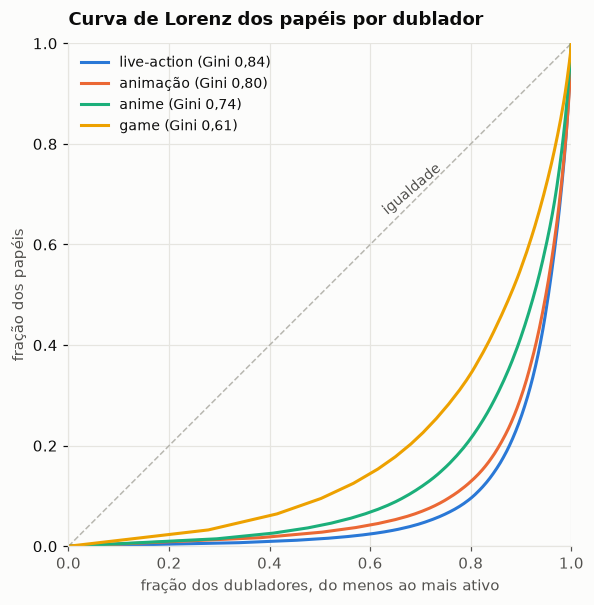

In [3]:
fig, ax = plt.subplots(figsize=(6.4, 5.6))
ax.plot([0, 1], [0, 1], color=ex.GRAY, linewidth=1, linestyle="--")
ax.text(0.62, 0.66, "igualdade", color=ex.INK2, fontsize=9, rotation=40)
grupos = ["live-action", "animação", "anime", "game"]
for cor, g in zip(CAT, grupos):
    xs, ys = q.lorenz(q.roles([r for r in rows if q.GRUPO.get(r["midia"]) == g]))
    gi = next(c["gini"] for c in conc if c["recorte"] == g)
    ax.plot(xs, ys, color=cor, linewidth=2, label=f"{g} (Gini {gi:.2f})".replace(".", ","))
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect("equal")
ax.set_xlabel("fração dos dubladores, do menos ao mais ativo"); ax.set_ylabel("fração dos papéis")
ax.set_title("Curva de Lorenz dos papéis por dublador")
ax.legend(loc="upper left", fontsize=9)
fig.tight_layout(); fig.savefig(FIGS / "01_lorenz.png", dpi=150, bbox_inches="tight")

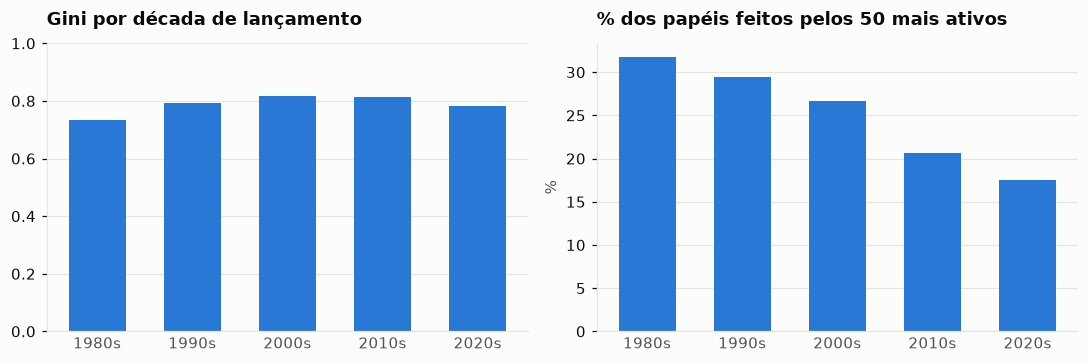

In [4]:
dec = [c for c in conc if c["recorte"].endswith("0s")]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].bar([c["recorte"] for c in dec], [c["gini"] for c in dec], width=0.6, color=ex.BLUE)
axes[0].set_title("Gini por década de lançamento"); axes[0].set_ylim(0, 1)
axes[1].bar([c["recorte"] for c in dec], [c["top 50"] for c in dec], width=0.6, color=ex.BLUE)
axes[1].set_title("% dos papéis feitos pelos 50 mais ativos"); axes[1].set_ylabel("%")
for ax in axes: ax.grid(axis="x", visible=False); ax.tick_params(axis="x", length=0)
fig.tight_layout()

**Achado.** A dublagem é muito concentrada: os 10% de dubladores mais ativos fazem 84% dos papéis, e o Gini geral é 0,88. Por década, a concentração é menor (cada década tem menos gente e menos "veteranos" acumulando carreira), sobe dos anos 80 (0,73) aos 2000 (0,82) e recua nos 2020 (0,78); a fatia dos 50 mais ativos cai de 32% para 18%, sinal de um elenco que se renovou e se espalhou por mais estúdios. Por mídia, live-action é a mais concentrada (0,84) e games a menos (0,61).

**Limitações.** "Papel" depende de quanto cada página detalha o elenco (obras com vozes adicionais listadas pesam mais). O Gini geral junta carreiras de 90 anos; o de cada década compara populações de tamanhos diferentes. A década é a do lançamento original, não a da dublagem.

## 2. O mapa da escalação

Grafo bipartido dublador–diretor de dublagem: uma aresta liga um dublador a um diretor quando trabalharam juntos em pelo menos 2 obras, com peso igual ao número de obras. Só entram as linhas em que o diretor está ligado à versão certa (`estudio_status` único ou casado). As comunidades vêm do algoritmo de Louvain (`networkx`, semente fixa). A cidade de cada pessoa vem das categorias "Dubladores do Rio de Janeiro" / "de São Paulo" da Dublapédia.

In [5]:
g = q.grafo_escalacao(rows)
com = q.comunidades(g)
cid = q.cidades()
tabela([("pessoas (nós)", mil(g.number_of_nodes())), ("ligações (arestas)", mil(g.number_of_edges())),
        ("comunidades", len(com)), ("pessoas com categoria de cidade", mil(sum(g.nodes[n]["nome"] in cid for n in g)))],
       ["", "total"])
pc = q.comunidades_por_cidade(g, com, cid, 8)
tabela(pc, ["comunidade", "pessoas", "diretores", "RJ", "SP", "RJ+SP", "sem", "cidade dominante", "pureza"], {"pureza": p1})
display(Markdown(f"**Pureza geral**: {p1(q.pureza_geral(g, com, cid))} das pessoas com uma só cidade estão numa comunidade da mesma cidade."))

|  | total |
|---|---:|
| pessoas (nós) | 3.341 |
| ligações (arestas) | 51.497 |
| comunidades | 16 |
| pessoas com categoria de cidade | 2.542 |

| comunidade | pessoas | diretores | RJ | SP | RJ+SP | sem | cidade dominante | pureza |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| 1 | 890 | 222 | 2 | 721 | 66 | 101 | SP | 91,4% |
| 2 | 714 | 81 | 12 | 506 | 61 | 135 | SP | 87,4% |
| 3 | 697 | 168 | 546 | 6 | 65 | 80 | RJ | 88,5% |
| 4 | 437 | 80 | 283 | 9 | 77 | 68 | RJ | 76,7% |
| 5 | 324 | 36 | 51 | 33 | 27 | 213 | RJ | 45,9% |
| 6 | 119 | 25 | 5 | 7 | 3 | 104 | SP | 46,7% |
| 7 | 61 | 8 | 8 | 0 | 1 | 52 | RJ | 88,9% |
| 8 | 38 | 4 | 0 | 23 | 14 | 1 | SP | 62,2% |

**Pureza geral**: 97,0% das pessoas com uma só cidade estão numa comunidade da mesma cidade.

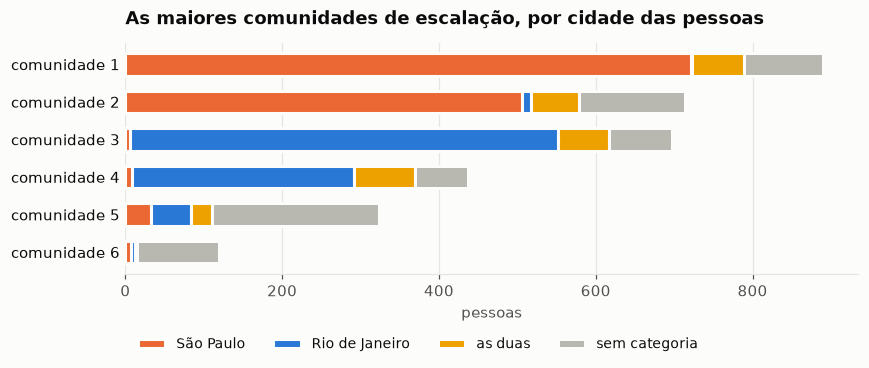

In [6]:
import networkx as nx
fig, ax = plt.subplots(figsize=(8, 3.6))
top = pc[:6]
left = [0] * len(top)
for col, nome, cor in [("SP", "São Paulo", CAT[1]), ("RJ", "Rio de Janeiro", CAT[0]), ("RJ+SP", "as duas", CAT[3]), ("sem", "sem categoria", ex.GRAY)]:
    vals = [c[col] for c in top]
    ax.barh([f"comunidade {c['comunidade']}" for c in top][::-1], vals[::-1], left=left[::-1], height=0.6, color=cor,
            edgecolor=ex.SURFACE, linewidth=2, label=nome)
    left = [l + v for l, v in zip(left, vals)]
ax.set_title("As maiores comunidades de escalação, por cidade das pessoas"); ax.set_xlabel("pessoas")
ax.grid(axis="y", visible=False); ax.tick_params(axis="y", length=0); ax.spines["left"].set_visible(False)
ax.legend(ncol=4, loc="upper left", bbox_to_anchor=(0, -0.22), fontsize=9)
fig.tight_layout(); fig.savefig(FIGS / "02_comunidades_cidade.png", dpi=150, bbox_inches="tight")

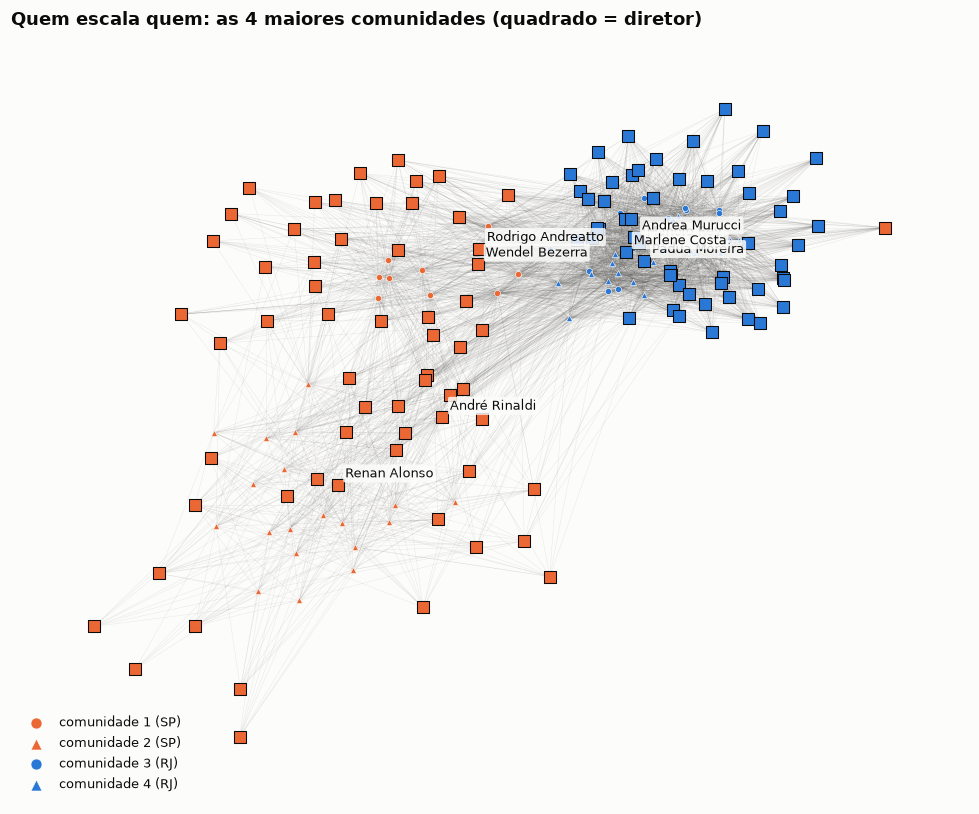

In [7]:
sub = q.subgrafo_desenho(g, com, n_com=4, por_com=45)
sub = sub.subgraph(max(nx.connected_components(sub), key=len)).copy()
idx = {n: i for i, c in enumerate(com[:4]) for n in c}
pos = nx.spring_layout(sub, weight="weight", seed=7, k=0.9 / len(sub) ** 0.5, iterations=300)
fig, ax = plt.subplots(figsize=(9, 7.5))
nx.draw_networkx_edges(sub, pos, ax=ax, width=0.3, alpha=0.12, edge_color=ex.INK2)
for i in range(4):
    nodes = [n for n in sub if idx.get(n) == i]
    cor = CAT[1] if pc[i]["cidade dominante"] == "SP" else CAT[0]
    forma = "o" if i in (0, 2) else "^"
    nx.draw_networkx_nodes(sub, pos, nodelist=[n for n in nodes if sub.nodes[n]["tipo"] == "dublador"], ax=ax, node_size=16,
                           node_shape=forma, node_color=cor, edgecolors=ex.SURFACE, linewidths=0.4,
                           label=f"comunidade {i + 1} ({pc[i]['cidade dominante']})")
    dirs = [n for n in nodes if sub.nodes[n]["tipo"] == "diretor"]
    nx.draw_networkx_nodes(sub, pos, nodelist=dirs, ax=ax, node_size=55, node_shape="s", node_color=cor,
                           edgecolors=ex.INK, linewidths=0.7)
    for n in sorted(dirs, key=lambda n: -g.degree(n, weight="weight"))[:2]:
        ax.annotate(sub.nodes[n]["nome"], pos[n], fontsize=8.5, color=ex.INK, xytext=(5, 5), textcoords="offset points",
                    bbox=dict(boxstyle="round,pad=0.15", fc=ex.SURFACE, ec="none", alpha=0.85))
ax.set_title("Quem escala quem: as 4 maiores comunidades (quadrado = diretor)")
ax.axis("off"); ax.legend(loc="lower left", fontsize=8.5, markerscale=1.8)
fig.tight_layout(); fig.savefig(FIGS / "02_escalacao_rede.png", dpi=150, bbox_inches="tight")

Diretores mais "fiéis" a um elenco: entre os diretores com 30 ou mais obras, a fração dos papéis que eles deram a dubladores com quem trabalharam em 5 ou mais obras.

Mediana entre os 113 diretores: **62%** dos papéis vão para o elenco fixo.

| diretor | obras | elenco fixo (pessoas) | % dos papéis |
|---|---:|---:|---:|
| Manolo Rey | 322 | 258 | 90,7% |
| Guilherme Briggs | 99 | 135 | 90,1% |
| Felipe Drummond | 132 | 181 | 89,4% |
| Pádua Moreira | 249 | 235 | 88,6% |
| Marlene Costa | 193 | 232 | 86,9% |
| Andrea Murucci | 188 | 192 | 86,7% |
| Marco Ribeiro | 95 | 206 | 86,4% |
| Gustavo Iglesias | 94 | 57 | 84,3% |

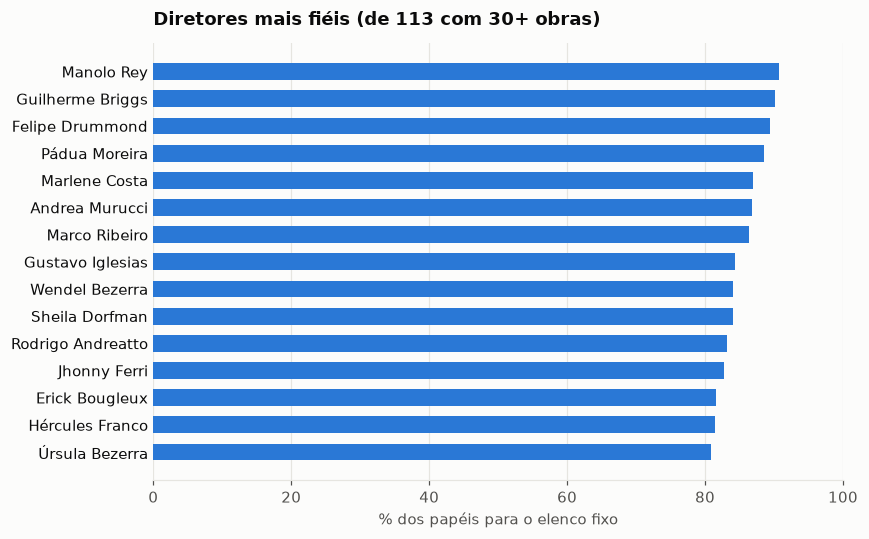

In [8]:
fieis, n_dir, dist = q.diretores_fieis(rows)
fig, ax = plt.subplots(figsize=(8, 5))
ex.barh(ax, [d for d, *_ in fieis], [p for *_, p in fieis], f"Diretores mais fiéis (de {n_dir} com 30+ obras)", "% dos papéis para o elenco fixo")
ax.set_xlim(0, 100)
fig.tight_layout()
display(Markdown(f"Mediana entre os {n_dir} diretores: **{dist[len(dist) // 2]:.0f}%** dos papéis vão para o elenco fixo."))
tabela(fieis[:8], ["diretor", "obras", "elenco fixo (pessoas)", "% dos papéis"], {"% dos papéis": p1})

**Achado.** A rede de escalação se divide quase perfeitamente entre Rio e São Paulo: as quatro maiores comunidades são duas paulistas e duas cariocas, cada uma com 77% a 91% das pessoas de uma só cidade, e 97% das pessoas com cidade conhecida caem numa comunidade da sua cidade. Os diretores trabalham com um elenco fixo: na mediana, 62% dos papéis de um diretor vão para dubladores com quem ele já trabalhou em 5 ou mais obras; Manolo Rey chega a 91%.

**Limitações.** A cidade vem só das categorias das fichas (sem categoria = "sem"); a 5ª comunidade, mais misturada e com dois terços das pessoas sem cidade, gira em torno de outros estúdios (Astrolábio Studio, All Dubbing Group, Dublagem Curitiba), em que a categoria de cidade quase não é usada. Louvain é estocástico; a semente e a ordem das arestas são fixas para o resultado ser reproduzível, mas outra semente pode mover a fronteira das comunidades pequenas. Obras com estúdio ambíguo (12% das linhas) ficam de fora do grafo.

## 3. Fidelidade de voz

Para cada ator original com pelo menos 3 obras numa mídia: em que fração das obras aparece o seu dublador brasileiro mais frequente? "Voz fixa" seria perto de 100%. Separo live-action (filmes, séries, novelas), animação ocidental, anime e games.

In [9]:
fid3, fid10 = q.fidelidade(rows, 3), q.fidelidade(rows, 10)
r3, r10 = q.resumo_fidelidade(fid3), q.resumo_fidelidade(fid10)
for r in r3: r["recorte"] = "3+ obras"
for r in r10: r["recorte"] = "10+ obras"
tabela(r3 + r10, ["recorte", "grupo", "atores", "mediana", "≥ 80%", "100%"], {"atores": mil, "mediana": p1, "≥ 80%": p1, "100%": p1})

| recorte | grupo | atores | mediana | ≥ 80% | 100% |
|---|---:|---:|---:|---:|---:|
| 3+ obras | anime | 2.270 | 20,0% | 1,9% | 1,6% |
| 3+ obras | live-action | 15.304 | 33,3% | 2,2% | 1,5% |
| 3+ obras | animação | 2.992 | 33,3% | 5,4% | 3,8% |
| 3+ obras | game | 572 | 42,9% | 14,5% | 13,6% |
| 10+ obras | anime | 954 | 10,8% | 0,1% | 0,1% |
| 10+ obras | live-action | 2.283 | 27,3% | 1,1% | 0,1% |
| 10+ obras | animação | 565 | 18,2% | 2,3% | 0,5% |
| 10+ obras | game | 47 | 16,7% | 0,0% | 0,0% |

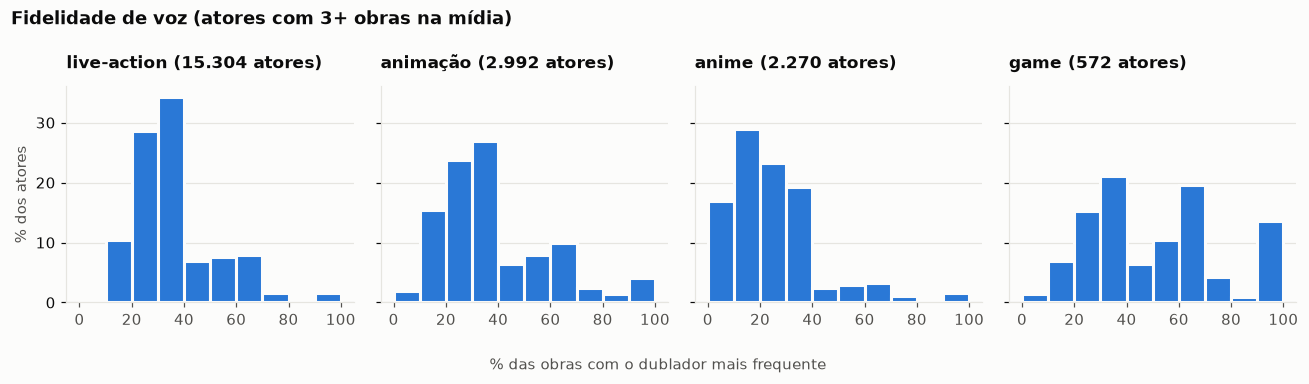

In [10]:
grupos = ["live-action", "animação", "anime", "game"]
fig, axes = plt.subplots(1, 4, figsize=(12, 3.4), sharey=True)
bins = list(range(0, 101, 10))
for ax, gname in zip(axes, grupos):
    v = fid3.get(gname, [])
    ax.hist(v, bins=bins, color=ex.BLUE, edgecolor=ex.SURFACE, linewidth=2, weights=[100 / len(v)] * len(v))
    ax.set_title(f"{gname} ({len(v):,} atores)".replace(",", "."), fontsize=11)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("% dos atores")
fig.supxlabel("% das obras com o dublador mais frequente", fontsize=10, color=ex.INK2)
fig.suptitle("Fidelidade de voz (atores com 3+ obras na mídia)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); fig.savefig(FIGS / "03_fidelidade.png", dpi=150, bbox_inches="tight")

A voz fixa existe, mas para poucos. Os atores de live-action com mais obras na base:

In [11]:
tabela(q.fidelidade_top(rows, "live-action", 12), ["ator original", "obras", "dublador mais frequente", "% das obras"], {"% das obras": p1})

| ator original | obras | dublador mais frequente | % das obras |
|---|---:|---:|---:|
| John Wayne | 68 | Márcio Seixas | 13,2% |
| Samuel L. Jackson | 67 | Márcio Simões | 73,1% |
| Robert De Niro | 57 | Hélio Ribeiro | 52,6% |
| Morgan Freeman | 57 | Márcio Simões | 33,3% |
| Harrison Ford | 55 | Garcia Júnior | 27,3% |
| Ricardo Vera | 54 | André Bellisar | 9,3% |
| Brad Pitt | 52 | Marco Antônio Costa | 55,8% |
| Liam Neeson | 51 | Dário de Castro | 23,5% |
| Tom Hanks | 51 | Marco Ribeiro | 70,6% |
| Adam Sandler | 50 | Alexandre Moreno | 78,0% |
| Benjamín Islas | 47 | Maurício Berger | 21,3% |
| Julia Roberts | 47 | Andrea Murucci | 38,3% |

Redublagens: o mesmo personagem, com o mesmo ator original, aparece em duas versões da mesma obra. Com que frequência o dublador muda?

In [12]:
red = q.redublagens(rows)
tabela([(k, mil(v["personagens"]), p1(v["% com dublador diferente"])) for k, v in red.items()],
       ["versões comparadas", "personagens", "% com dublador diferente"])

| versões comparadas | personagens | % com dublador diferente |
|---|---:|---:|
| temporadas | 280 | 81,1% |
| dublagens diferentes | 21.516 | 92,5% |

**Achado.** A "voz fixa" é a exceção: entre atores de live-action com 3 ou mais obras, a mediana é de 33% das obras com o mesmo dublador, e só 2% passam de 80%. Os casos clássicos aparecem no topo (Adam Sandler com Alexandre Moreno em 78% das obras, Samuel L. Jackson com Márcio Simões em 73%, Tom Hanks com Marco Ribeiro em 71%), mas atores com carreira longa em muitas épocas, como John Wayne, se espalham por dezenas de vozes. No anime a fidelidade é ainda menor (mediana de 20%), porque a seiyuu faz personagens diferentes e cada um ganha sua voz. Em redublagens, o dublador muda em 93% dos personagens.

**Limitações.** A fidelidade conta obras, não personagens; um ator com duas dublagens da mesma obra conta a obra como "fiel" se o dublador mais frequente aparece em qualquer uma. Atores sem ficha podem estar divididos em grafias diferentes, o que baixa a fidelidade. "Temporadas" tem poucos casos (280) e mistura troca de estúdio com troca de elenco.

## 4. Gênero

O gênero do dublador está em 99% dos papéis (98% pela ficha, 1% pelo primeiro nome). O do ator original só existe para quem tem ficha na Dublapédia (27% dos papéis), o que inclui as seiyuus.

**33,7%** dos 369.398 papéis com gênero são feitos por dubladoras.

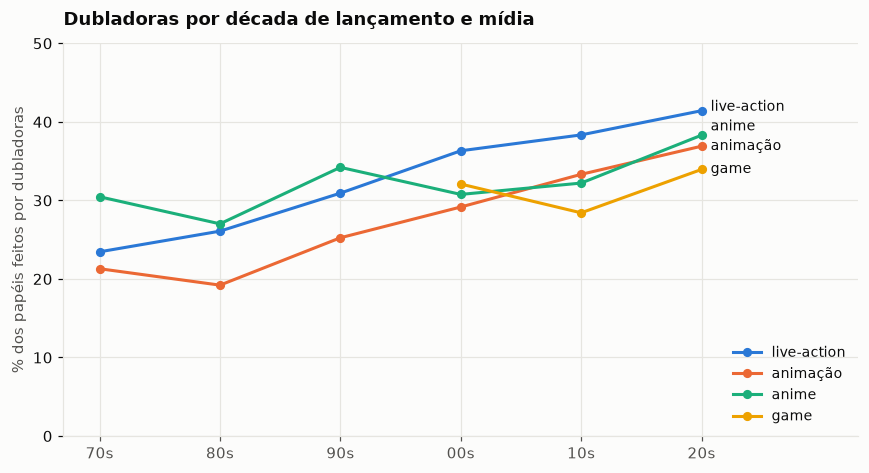

In [13]:
geral = q.pct_dubladoras(rows, lambda r: "todos")["todos"]
display(Markdown(f"**{p1(geral[0])}** dos {mil(geral[1])} papéis com gênero são feitos por dubladoras."))
md = q.por_midia_decada(rows)
fig, ax = plt.subplots(figsize=(8, 4.4))
fins = []
for cor, gname in zip(CAT, ["live-action", "animação", "anime", "game"]):
    serie = md.get(gname, {})
    if not serie: continue
    xs, ys = list(serie), list(serie.values())
    ax.plot(xs, ys, color=cor, linewidth=2, marker="o", markersize=5, label=gname)
    fins.append([ys[-1], gname, xs[-1]])
fins.sort()
for i in range(1, len(fins)):  # afasta rótulos que colidiriam (mínimo de 2,5 pontos)
    fins[i][0] = max(fins[i][0], fins[i - 1][0] + 2.5)
for y, nome, x in fins:
    ax.annotate(nome, (x, y), xytext=(6, 0), textcoords="offset points", va="center", fontsize=9, color=ex.INK)
ax.set_ylim(0, 50); ax.set_xlim(min(min(v) for v in md.values()) - 3, 2033)
ax.set_xticks([1970, 1980, 1990, 2000, 2010, 2020], ["70s", "80s", "90s", "00s", "10s", "20s"])
ax.set_ylabel("% dos papéis feitos por dubladoras"); ax.set_title("Dubladoras por década de lançamento e mídia")
ax.legend(loc="lower right", fontsize=9)
fig.tight_layout(); fig.savefig(FIGS / "04_genero_decada.png", dpi=150, bbox_inches="tight")

Gênero cruzado: papéis de atores originais homens feitos por dubladoras, e de atrizes ou seiyuus mulheres feitos por dubladores homens.

In [14]:
gc = q.genero_cruzado(rows)
tabela([(k, mil(v["atores homens"]), p1(v["% dublados por mulheres"]), mil(v["atrizes"]), p1(v["% dubladas por homens"])) for k, v in gc.items()],
       ["mídia", "papéis de atores homens", "% com dubladora", "papéis de atrizes", "% com dublador"])
casos = []
for nome in ("Masako Nozawa", "Mayumi Tanaka", "Junko Takeuchi", "Megumi Ogata"):
    gen, top = q.seiyuu(rows, nome)
    casos.append((nome, gen.get("M", 0), gen.get("F", 0), ", ".join(f"{d} ({n})" for d, n in top[:3])))
tabela(casos, ["seiyuu", "papéis com dublador", "papéis com dubladora", "dubladores mais frequentes"])

| mídia | papéis de atores homens | % com dubladora | papéis de atrizes | % com dublador |
|---|---:|---:|---:|---:|
| live-action | 31.414 | 0,4% | 18.691 | 0,3% |
| animação | 17.929 | 2,4% | 6.656 | 7,1% |
| anime | 7.917 | 2,1% | 5.576 | 13,4% |
| game | 1.693 | 1,6% | 516 | 3,1% |

| seiyuu | papéis com dublador | papéis com dubladora | dubladores mais frequentes |
|---|---:|---:|---:|
| Masako Nozawa | 78 | 63 | Wendel Bezerra (29), Fátima Noya (24), Vagner Fagundes (15) |
| Mayumi Tanaka | 46 | 31 | Fábio Lucindo (18), Carol Valença (9), Vagner Fagundes (5) |
| Junko Takeuchi | 21 | 28 | Ursula Bezerra (10), Yuri Chesman (7), Pamella Rodrigues (3) |
| Megumi Ogata | 39 | 31 | Fábio Lucindo (13), Rodrigo Andreatto (4), Fátima Noya (3) |

In [15]:
pa = q.principal_vs_adicional(rows)
tabela([(k, p1(v[0]), mil(v[1])) for k, v in pa.items()], ["seção da página", "% dubladoras", "papéis"])

| seção da página | % dubladoras | papéis |
|---|---:|---:|
| elenco principal | 34,2% | 309.846 |
| vozes adicionais / participações | 31,5% | 59.552 |

**Achado.** Dubladoras fazem 34% dos papéis, e a fatia cresce em todas as mídias: no live-action, de 23% nas obras dos anos 70 para 41% nas dos anos 2020; na animação, de 21% para 37%. Mulheres dublando atores homens é raro mesmo no anime (2%). O caso mais comum é o inverso: seiyuus mulheres que fazem meninos no Japão ganham um dublador homem no Brasil em 13% dos papéis de atrizes no anime. Masako Nozawa (Goku) tem 78 papéis com dubladores homens, a maioria com Wendel Bezerra. Naruto (Junko Takeuchi → Úrsula Bezerra) é a exceção que manteve a voz feminina. No elenco principal, 34% dos papéis são de dubladoras; nas vozes adicionais, 32%.

**Limitações.** O gênero do ator original só existe para quem tem ficha (27% dos papéis), um recorte que favorece atores famosos e seiyuus. "Elenco principal x vozes adicionais" usa o nome da seção da página (heurística: "Vozes Adicionais", "Participações", "Episódicos"…), e muitas páginas não fazem essa separação. O gênero do ator original é um proxy do personagem, que falha justamente no anime.